In [1]:
%load_ext autoreload
%autoreload 2

In [29]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import HTML, display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from introml_myocardial_infarction import CardiacDataLoader, DataTransformations

import sys
from pathlib import Path


# Locate the project from either the repository or notebooks folder.
project_root = Path.cwd()
if not (project_root / "pyproject.toml").is_file():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.models.model import create_random_forest, create_catboost

data_dir = project_root / "data" / "training_data"
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11})


# Logistic Regression: PCA on full data

In [64]:
loader = CardiacDataLoader(data_dir)

data = loader.load_all(
    frames=slice(None),
    surfaces=np.array([0, 1, 2])
)

demographics = data.drop(
    columns=["point_cloud", "surface_codes"]
)

stacked_data = DataTransformations.stack_data(
    data["point_cloud"]
)

X_spatial = stacked_data.reshape(stacked_data.shape[0], -1)

y = demographics["MI"].to_numpy()

demographics = demographics.drop(columns=["MI"])

X_metadata = demographics.to_numpy()

# Concatenate spatial and metadata features
X = np.concatenate(
    [X_spatial, X_metadata],
    axis=1
)


In [65]:
X.shape, y.shape

((900, 540007), (900,))

In [66]:
results = cross_validate(
    X=X,
    y=y,
    n_splits=5,
    n_spatial_features=X_spatial.shape[1]
)

/Users/sbaum/CDT/IntroML/introml_myocardial_infarction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold 1: {'accuracy': 0.7722222222222223, 'precision': 0.7736837011227254, 'recall': 0.7722222222222223, 'f1': 0.7717782109594974}


/Users/sbaum/CDT/IntroML/introml_myocardial_infarction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold 2: {'accuracy': 0.7944444444444444, 'precision': 0.7976425529561418, 'recall': 0.7944444444444444, 'f1': 0.7940441476993669}
Fold 3: {'accuracy': 0.7777777777777778, 'precision': 0.7783275606135577, 'recall': 0.7777777777777778, 'f1': 0.7776679841897233}


/Users/sbaum/CDT/IntroML/introml_myocardial_infarction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold 4: {'accuracy': 0.8055555555555556, 'precision': 0.8074152279219973, 'recall': 0.8055555555555556, 'f1': 0.8052610429353033}


/Users/sbaum/CDT/IntroML/introml_myocardial_infarction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold 5: {'accuracy': 0.8444444444444444, 'precision': 0.8451261751608115, 'recall': 0.8444444444444444, 'f1': 0.8443675889328063}

Cross-validation results:
accuracy: 0.7989 ± 0.0257
precision: 0.8004 ± 0.0255
recall: 0.7989 ± 0.0257
f1: 0.7986 ± 0.0258


# RF: PCA on full data

In [14]:
loader = CardiacDataLoader(data_dir)

data = loader.load_all(
    frames=slice(None),
    surfaces=np.array([0, 1, 2])
)

demographics = data.drop(
    columns=["point_cloud", "surface_codes"]
)

stacked_data = DataTransformations.stack_data(
    data["point_cloud"]
)

X_spatial = stacked_data.reshape(stacked_data.shape[0], -1)

y = demographics["MI"].to_numpy()

demographics = demographics.drop(columns=["MI"])

X_metadata = demographics.to_numpy()

# Concatenate spatial and metadata features
X = np.concatenate(
    [X_spatial, X_metadata],
    axis=1
)


In [15]:
X.shape, y.shape

((900, 540007), (900,))

In [17]:
results = cross_validate(
    X=X,
    y=y,
    n_splits=5,
    n_spatial_features=X_spatial.shape[1],
    model_func=create_random_forest
)

Fold 1: {'accuracy': 0.8166666666666667, 'precision': 0.8253994560598336, 'recall': 0.8166666666666667, 'f1': 0.8152107792760529, 'auc': 0.9172737374984565}
Fold 2: {'accuracy': 0.8222222222222222, 'precision': 0.8222222222222222, 'recall': 0.8222222222222222, 'f1': 0.8222222222222222, 'auc': 0.9162859612297815}
Fold 3: {'accuracy': 0.8444444444444444, 'precision': 0.8459821428571429, 'recall': 0.8444444444444444, 'f1': 0.8442714126807563, 'auc': 0.9209876543209877}
Fold 4: {'accuracy': 0.8777777777777778, 'precision': 0.8777777777777778, 'recall': 0.8777777777777778, 'f1': 0.8777777777777778, 'auc': 0.9351851851851851}
Fold 5: {'accuracy': 0.8722222222222222, 'precision': 0.8744876412867967, 'recall': 0.8722222222222222, 'f1': 0.8720286853574849, 'auc': 0.9454320987654321}

Cross-validation results:
accuracy: 0.8467 ± 0.0250
precision: 0.8492 ± 0.0235
recall: 0.8467 ± 0.0250
f1: 0.8463 ± 0.0253
auc: 0.9270 ± 0.0114


# Logistic Regression: PCA on diff

In [67]:
loader = CardiacDataLoader(data_dir)

data = loader.load_all(
    frames=slice(None),
    surfaces=np.array([0, 1, 2])
)

demographics = data.drop(
    columns=["point_cloud", "surface_codes"]
)

stacked_data = DataTransformations.get_stacked_deltas(
    data["point_cloud"]
)

X_spatial = stacked_data.reshape(stacked_data.shape[0], -1)

y = demographics["MI"].to_numpy()

demographics = demographics.drop(columns=["MI"])

X_metadata = demographics.to_numpy()

# Concatenate spatial and metadata features
X = np.concatenate(
    [X_spatial, X_metadata],
    axis=1
)


In [68]:
X.shape, y.shape

((900, 486007), (900,))

In [69]:
results = cross_validate(
    X=X,
    y=y,
    n_splits=5,
    n_spatial_features=X_spatial.shape[1]
)

Fold 1: {'accuracy': 0.75, 'precision': 0.7513066202090593, 'recall': 0.75, 'f1': 0.7495126705653021}
Fold 2: {'accuracy': 0.7666666666666667, 'precision': 0.7667408231368187, 'recall': 0.7666666666666667, 'f1': 0.7666090250329382}
Fold 3: {'accuracy': 0.7611111111111111, 'precision': 0.7637485970819303, 'recall': 0.7611111111111111, 'f1': 0.7605123920913394}
Fold 4: {'accuracy': 0.8166666666666667, 'precision': 0.8167057661439684, 'recall': 0.8166666666666667, 'f1': 0.8166610080558042}


/Users/sbaum/CDT/IntroML/introml_myocardial_infarction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold 5: {'accuracy': 0.7888888888888889, 'precision': 0.7894606630380999, 'recall': 0.7888888888888889, 'f1': 0.7887845849802372}

Cross-validation results:
accuracy: 0.7767 ± 0.0237
precision: 0.7776 ± 0.0231
recall: 0.7767 ± 0.0237
f1: 0.7764 ± 0.0239


# Logistic Regression: PCA on diff from zero

In [3]:
loader = CardiacDataLoader(data_dir)

data = loader.load_all(
    frames=slice(None),
    surfaces=np.array([0, 1, 2])
)

demographics = data.drop(
    columns=["point_cloud", "surface_codes"]
)

stacked_data = DataTransformations.get_stacked_deltas_from_zero(
    data["point_cloud"]
)

X_spatial = stacked_data.reshape(stacked_data.shape[0], -1)

y = demographics["MI"].to_numpy()

demographics = demographics.drop(columns=["MI"])

X_metadata = demographics.to_numpy()

# Concatenate spatial and metadata features
X = np.concatenate(
    [X_spatial, X_metadata],
    axis=1
)


In [4]:
X.shape, y.shape

((900, 486007), (900,))

In [5]:
results = cross_validate(
    X=X,
    y=y,
    n_splits=5,
    n_spatial_features=X_spatial.shape[1]
)

Fold 1: {'accuracy': 0.7277777777777777, 'precision': 0.7289295392953928, 'recall': 0.7277777777777777, 'f1': 0.7272471301711068, 'auc': 0.7913322632423756}
Fold 2: {'accuracy': 0.7666666666666667, 'precision': 0.766855990451496, 'recall': 0.7666666666666667, 'f1': 0.7666666666666667, 'auc': 0.8461538461538461}


/Users/sbaum/CDT/IntroML/introml_myocardial_infarction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold 3: {'accuracy': 0.7777777777777778, 'precision': 0.7790178571428571, 'recall': 0.7777777777777778, 'f1': 0.7775305895439377, 'auc': 0.8114814814814814}
Fold 4: {'accuracy': 0.7777777777777778, 'precision': 0.7790178571428571, 'recall': 0.7777777777777778, 'f1': 0.7775305895439377, 'auc': 0.8006172839506174}
Fold 5: {'accuracy': 0.8111111111111111, 'precision': 0.8111111111111111, 'recall': 0.8111111111111111, 'f1': 0.8111111111111111, 'auc': 0.8412345679012346}

Cross-validation results:
accuracy: 0.7722 ± 0.0268
precision: 0.7730 ± 0.0265
recall: 0.7722 ± 0.0268
f1: 0.7720 ± 0.0269
auc: 0.8182 ± 0.0219


# Tests

In [37]:
import numpy as np

from src.models.model import create_model
from src.training.trainer import train_model, evaluate_model

def prepare_data(data):
    demographics = data.drop(
        columns=["point_cloud", "surface_codes"]
    )

    stacked = DataTransformations.stack_data(
        data["point_cloud"]
    )

    X_spatial = stacked.reshape(stacked.shape[0], -1)

    y = (demographics["MI"] == "pMI").astype(int).to_numpy()

    demographics = demographics.drop(columns=["MI"])
    metadata_cols = demographics.columns

    X_metadata = demographics.astype(float).to_numpy()


    # Concatenate spatial and metadata features
    X = np.concatenate(
        [X_spatial, X_metadata],
        axis=1
    )
    return X, y, metadata_cols


In [38]:
train_dir = project_root / "data" / "training_data"

test_dir = project_root / "data" / "testing_data"

train_loader = CardiacDataLoader(train_dir)
test_loader = CardiacDataLoader(test_dir)

train_data = train_loader.load_all(
    frames=slice(None),
    surfaces=np.array([0, 1, 2])
)

test_data = test_loader.load_all(
    frames=slice(None),
    surfaces=np.array([0, 1, 2])
)

In [39]:
X_train, y_train, metadata_cols = prepare_data(train_data)
X_test, y_test, metadata_cols = prepare_data(test_data)

In [52]:
from utils import run_experiments

models  = {
    "Logistic Regression": create_model,
    "Random Forest": create_random_forest,
    "CatBoost": create_catboost,
}

trained_models, results, summary = run_experiments(
    X_train=X_train,
    y_train=y_train,
    metadata_cols=metadata_cols,
    model_factories=models,
    X_test=X_test,
    y_test=y_test,
    mode="cv",  # Change to "cv" for cross-validation
    n_splits=5,
    n_pca_components=50,
)


Logistic Regression | CV


/Users/sbaum/CDT/IntroML/introml_myocardial_infarction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold 1: AUC=0.8513, AUPR=0.8270


/Users/sbaum/CDT/IntroML/introml_myocardial_infarction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold 2: AUC=0.8878, AUPR=0.8473
Fold 3: AUC=0.8610, AUPR=0.8713


/Users/sbaum/CDT/IntroML/introml_myocardial_infarction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold 4: AUC=0.8607, AUPR=0.8451


/Users/sbaum/CDT/IntroML/introml_myocardial_infarction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold 5: AUC=0.8838, AUPR=0.8654

Random Forest | CV
Fold 1: AUC=0.9173, AUPR=0.9188
Fold 2: AUC=0.9163, AUPR=0.9136
Fold 3: AUC=0.9210, AUPR=0.9218
Fold 4: AUC=0.9352, AUPR=0.9313
Fold 5: AUC=0.9454, AUPR=0.9368

CatBoost | CV
Fold 1: AUC=0.9448, AUPR=0.9474
Fold 2: AUC=0.9474, AUPR=0.9403
Fold 3: AUC=0.9462, AUPR=0.9427
Fold 4: AUC=0.9565, AUPR=0.9466
Fold 5: AUC=0.9737, AUPR=0.9698


,accuracy,precision,recall,f1,auc,aupr
Logistic Regression,0.8000,0.8015,0.8000,0.7997,0.8689,0.8512
Random Forest,0.8467,0.8492,0.8467,0.8463,0.9270,0.9245
CatBoost,0.8811,0.8852,0.8811,0.8807,0.9537,0.9494



Logistic Regression | TEST

Logistic Regression - Test Results:
accuracy: 0.6500
precision: 0.6503
recall: 0.6500
f1: 0.6501
auc: 0.6611
aupr: 0.6862


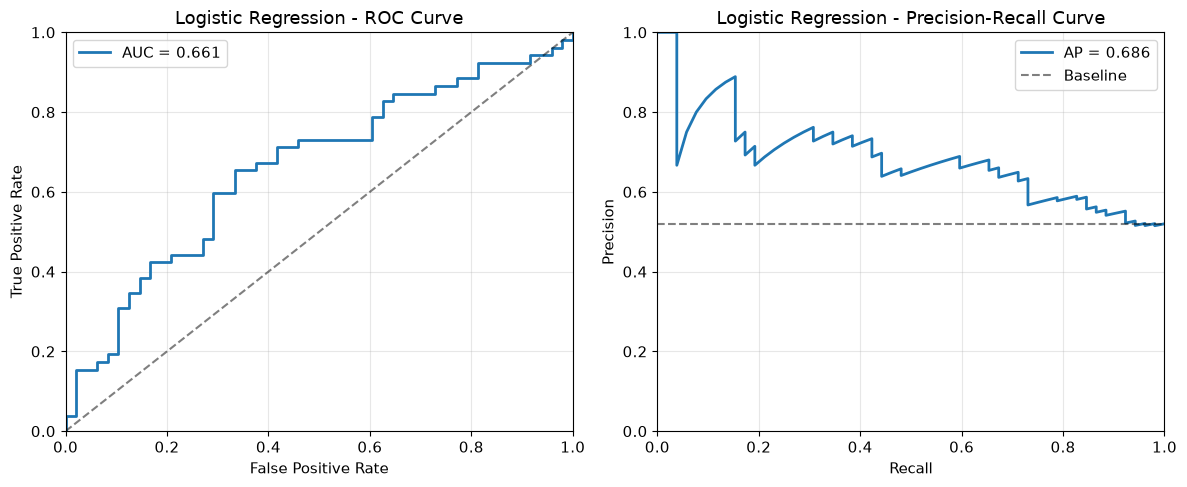


Random Forest | TEST

Random Forest - Test Results:
accuracy: 0.7000
precision: 0.6998
recall: 0.7000
f1: 0.6996
auc: 0.7612
aupr: 0.7946


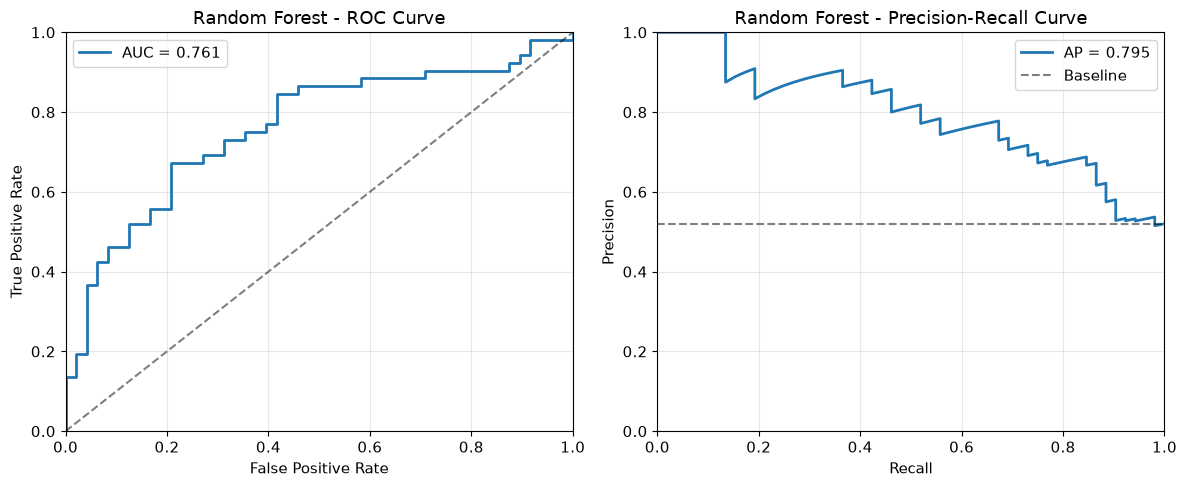


CatBoost | TEST

CatBoost - Test Results:
accuracy: 0.6200
precision: 0.6200
recall: 0.6200
f1: 0.6200
auc: 0.6943
aupr: 0.7493


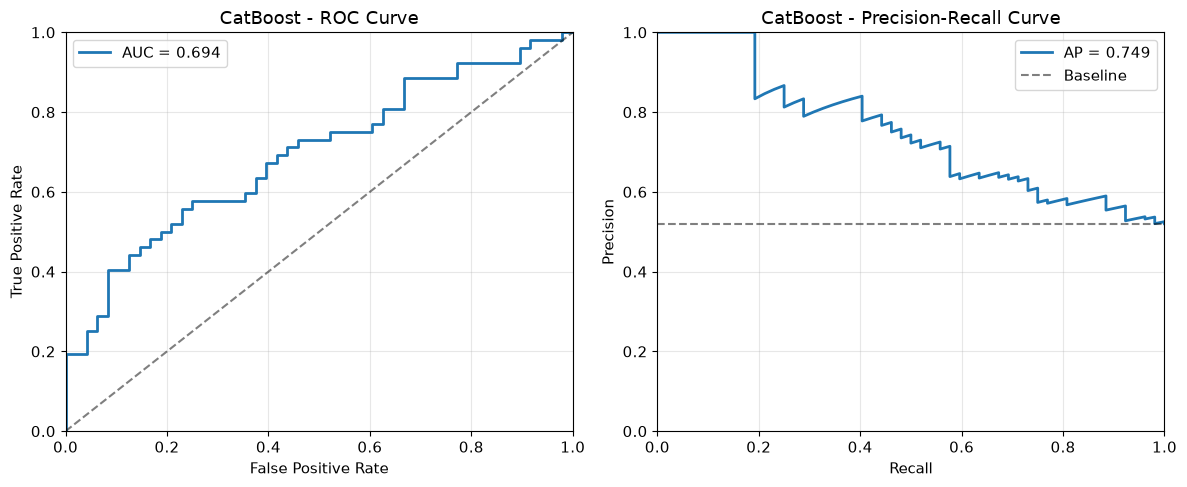

,accuracy,precision,recall,f1,auc,aupr
Logistic Regression,0.65,0.6503,0.65,0.6501,0.6611,0.6862
Random Forest,0.70,0.6998,0.70,0.6996,0.7612,0.7946
CatBoost,0.62,0.6200,0.62,0.6200,0.6943,0.7493


In [54]:
trained_models, results, summary = run_experiments(
    X_train=X_train,
    y_train=y_train,
    metadata_cols=metadata_cols,
    model_factories=models,
    X_test=X_test,
    y_test=y_test,
    mode="test",  # Change to "cv" for cross-validation
    n_splits=5,
    n_pca_components=50,
)

In [56]:
from src.models.model import create_random_forest
from utils import tune_model

rf_params = {
    "preprocessor__spatial__pca__n_components": [20, 50, 100],
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_leaf": [1, 3, 5, 10],
    "classifier__max_features": ["sqrt", 0.5, 1.0],
    "classifier__class_weight": [None, "balanced"],
}

best_rf, rf_search, rf_tuning_results = tune_model(
    create_fn=create_random_forest,
    param_distributions=rf_params,
    X_train=X_train,
    y_train=y_train,
    metadata_cols=metadata_cols,
    n_iter=20,
    n_splits=5,
    scoring="roc_auc",
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END classifier__class_weight=None, classifier__max_depth=5, classifier__max_features=sqrt, classifier__min_samples_leaf=5, classifier__n_estimators=100, preprocessor__spatial__pca__n_components=20; total time=  12.9s
[CV] END classifier__class_weight=None, classifier__max_depth=5, classifier__max_features=sqrt, classifier__min_samples_leaf=5, classifier__n_estimators=100, preprocessor__spatial__pca__n_components=20; total time=  10.8s
[CV] END classifier__class_weight=None, classifier__max_depth=5, classifier__max_features=sqrt, classifier__min_samples_leaf=5, classifier__n_estimators=100, preprocessor__spatial__pca__n_components=20; total time=   8.5s
[CV] END classifier__class_weight=None, classifier__max_depth=5, classifier__max_features=sqrt, classifier__min_samples_leaf=5, classifier__n_estimators=100, preprocessor__spatial__pca__n_components=20; total time=   7.3s
[CV] END classifier__class_weight=None, classifier

,mean_test_score,std_test_score,mean_train_score,params
1,0.939281,0.011519,0.999938,{'preprocessor__spatial__pca__n_components': 1...
8,0.936564,0.015341,0.997883,{'preprocessor__spatial__pca__n_components': 1...
10,0.929354,0.012968,0.999997,{'preprocessor__spatial__pca__n_components': 5...
12,0.926613,0.016851,0.999997,{'preprocessor__spatial__pca__n_components': 1...
15,0.924687,0.016825,1.000000,{'preprocessor__spatial__pca__n_components': 2...
4,0.923613,0.015865,1.000000,{'preprocessor__spatial__pca__n_components': 5...
19,0.920638,0.016323,0.999867,{'preprocessor__spatial__pca__n_components': 1...
16,0.918736,0.017573,1.000000,{'preprocessor__spatial__pca__n_components': 1...
2,0.916736,0.015920,0.999988,{'preprocessor__spatial__pca__n_components': 1...
18,0.913872,0.022235,0.997375,{'preprocessor__spatial__pca__n_components': 2...


In [57]:
best_rf

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,540007
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('spatial', ...), ('metadata', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outpu


Tuned Random Forest - Test Results:
accuracy: 0.6900
precision: 0.6903
recall: 0.6900
f1: 0.6901
auc: 0.7248
aupr: 0.7829


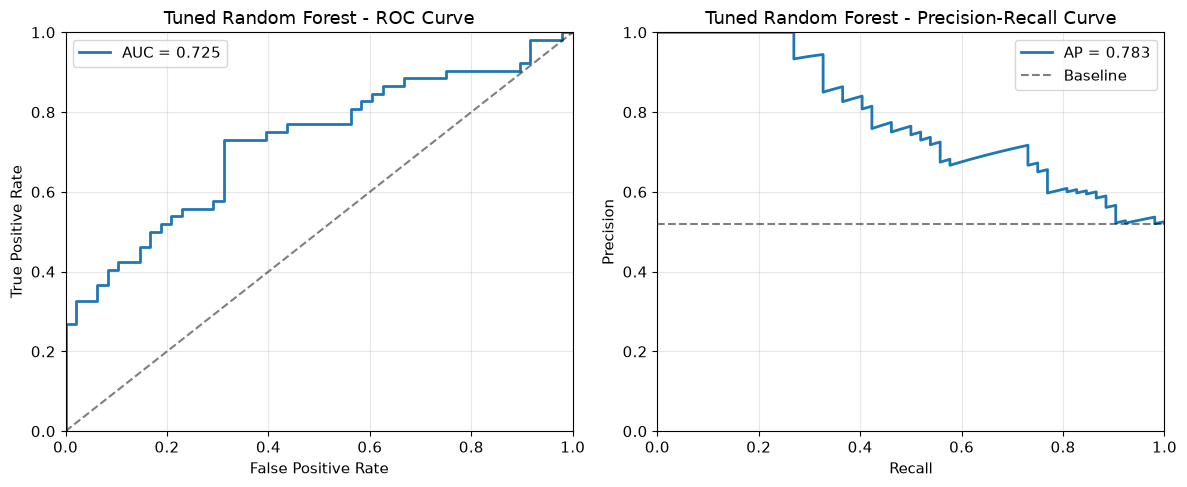

In [58]:
from utils import plot_model_results

rf_test_metrics = plot_model_results(
    best_rf,
    X_test,
    y_test,
    model_name="Tuned Random Forest",
)

In [ ]:
import joblib
from pathlib import Path

output_dir = Path("../results/random_forest")
output_dir.mkdir(parents=True, exist_ok=True)

# Save fitted model (includes PCA and preprocessing)
joblib.dump(best_rf, output_dir / "best_model.joblib")

# Save best hyperparameters and CV score
joblib.dump({
    "best_params": rf_search.best_params_,
    "best_cv_auc": rf_search.best_score_,
}, output_dir / "best_params.joblib")

# Save all hyperparameter search results
rf_tuning_results.to_csv(
    output_dir / "tuning_results.csv",
    index=False,
)

print(f"Saved results to {output_dir.resolve()}")

Saved results to /Users/sbaum/CDT/IntroML/introml_myocardial_infarction/outputs/random_forest
